# 01 Exploratory Data Analysis (EDA)

**Project:** Network Intrusion Detection Using Machine Learning  
**Dataset:** UNSW-NB15  

This notebook performs exploratory analysis on the UNSW-NB15 dataset:
1. Dataset shape, datatypes, and missing/infinite value audit.
2. Data cleaning, duplicate row removal, and whitespace stripping via `src.data_loader`.
3. Binary (`label`) and multi-class (`attack_cat`) target class distributions.
4. Correlation heatmap across key numeric traffic features.
5. Feature distributions (Normal vs Attack traffic).
6. Categorical frequency distributions for `proto`, `service`, and `state`.
7. Serialization of cleaned datasets to `data/processed/` and sample generation to `data/sample/`.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Add project root to sys.path
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import config, data_loader

# Configure clean styling for matplotlib / seaborn
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100
print('Environment initialized and src imported successfully.')

Environment initialized and src imported successfully.


## 1. Load Raw Dataset Splits

In [2]:
train_raw, test_raw = data_loader.load_raw()
print(f'Raw Training Split: {train_raw.shape[0]:,} rows x {train_raw.shape[1]} columns')
print(f'Raw Testing Split:  {test_raw.shape[0]:,} rows x {test_raw.shape[1]} columns')

2026-10-29 01:08:41,237 [INFO] Loading raw training set from: C:\Users\Ankit007\OneDrive\Documents\final year project\data\raw\UNSW_NB15_training-set.csv


2026-10-29 01:08:42,183 [INFO] Loaded raw training set with shape: (175341, 45)


2026-10-29 01:08:42,184 [INFO] Loading raw testing set from: C:\Users\Ankit007\OneDrive\Documents\final year project\data\raw\UNSW_NB15_testing-set.csv


2026-10-29 01:08:42,597 [INFO] Loaded raw testing set with shape: (82332, 45)


Raw Training Split: 175,341 rows x 45 columns
Raw Testing Split:  82,332 rows x 45 columns


## 2. Dataset Schema, Data Types, and Missing Values Audit

In [3]:
print('--- Column Data Types ---')
print(train_raw.dtypes.value_counts())

print('\n--- Categorical Columns Identified ---')
print(config.CATEGORICAL_COLS)

print('\n--- Missing (NaN) Values Audit ---')
train_nulls = train_raw.isna().sum()
test_nulls = test_raw.isna().sum()
print(f'Train missing columns: {train_nulls[train_nulls > 0].to_dict() or "None"}')
print(f'Test missing columns:  {test_nulls[test_nulls > 0].to_dict() or "None"}')

print('\n--- Infinite Values Audit ---')
numeric_cols = train_raw.select_dtypes(include=[np.number]).columns.tolist()
train_infs = int(np.isinf(train_raw[numeric_cols].to_numpy()).sum())
test_infs = int(np.isinf(test_raw[numeric_cols].to_numpy()).sum())
print(f'Train infinite values: {train_infs}')
print(f'Test infinite values:  {test_infs}')

--- Column Data Types ---
int64      30
float64    11
str         4
Name: count, dtype: int64

--- Categorical Columns Identified ---
['proto', 'service', 'state']

--- Missing (NaN) Values Audit ---
Train missing columns: None
Test missing columns:  None

--- Infinite Values Audit ---
Train infinite values: 0
Test infinite values:  0


## 3. Data Cleaning and Deduplication

We clean the dataset via `src.data_loader.clean`: stripping string whitespace, standardizing category labels, and removing duplicate connection records (excluding the artificial `id` column).

In [4]:
train_clean = data_loader.clean(train_raw)
test_clean = data_loader.clean(test_raw)

print('\nSummary after deduplication and cleaning:')
print(f'Cleaned Training Split: {train_clean.shape[0]:,} rows (retained {(len(train_clean)/len(train_raw))*100:.1f}%)')
print(f'Cleaned Testing Split:  {test_clean.shape[0]:,} rows (retained {(len(test_clean)/len(test_raw))*100:.1f}%)')

2026-10-29 01:08:42,803 [INFO] Starting cleaning pipeline on DataFrame with 175341 rows and 45 columns


2026-10-29 01:08:42,880 [INFO] No infinite values found in numeric columns


2026-10-29 01:08:42,889 [INFO] No NaN values found in DataFrame


2026-10-29 01:08:43,280 [INFO] Removing 67601 duplicate rows (identified across all feature/target columns excluding 'id')


2026-10-29 01:08:43,313 [INFO] Cleaning finished: 107740 rows retained, 67601 rows removed (38.55% of initial rows)


...

2026-10-29 01:08:43,390 [INFO] No infinite values found in numeric columns


2026-10-29 01:08:43,394 [INFO] No NaN values found in DataFrame


2026-10-29 01:08:43,551 [INFO] Removing 26387 duplicate rows (identified across all feature/target columns excluding 'id')


2026-10-29 01:08:43,567 [INFO] Cleaning finished: 55945 rows retained, 26387 rows removed (32.05% of initial rows)



Summary after deduplication and cleaning:
Cleaned Training Split: 107,740 rows (retained 61.4%)
Cleaned Testing Split:  55,945 rows (retained 68.0%)


## 4. Class Distributions: Binary and Multi-Class Targets

Binary Target Distribution:
     Label  Count  Percentage (%)
Normal (0)  51890           48.16
Attack (1)  55850           51.84

Multi-Class Target Distribution:
Attack Category  Count  Percentage (%)
         Normal  51890           48.16
       Exploits  19844           18.42
        Fuzzers  16150           14.99
 Reconnaissance   7522            6.98
        Generic   4181            3.88
            DoS   3806            3.53
       Analysis   1594            1.48
       Backdoor   1535            1.42
      Shellcode   1091            1.01
          Worms    127            0.12


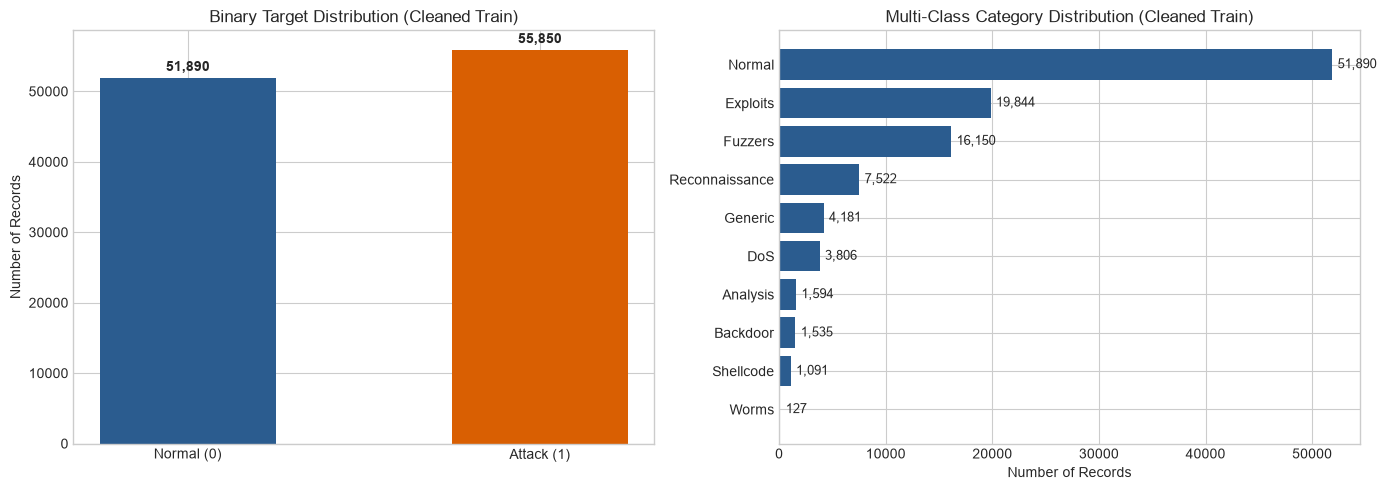

In [5]:
# Binary Target Distribution
binary_counts = train_clean[config.BINARY_TARGET].value_counts()
binary_df = pd.DataFrame({
    'Label': ['Normal (0)', 'Attack (1)'],
    'Count': [binary_counts.get(0, 0), binary_counts.get(1, 0)],
    'Percentage (%)': [
        round(binary_counts.get(0, 0) / len(train_clean) * 100, 2),
        round(binary_counts.get(1, 0) / len(train_clean) * 100, 2)
    ]
})
print('Binary Target Distribution:')
print(binary_df.to_string(index=False))

# Multi-Class Target Distribution
multi_counts = train_clean[config.MULTI_TARGET].value_counts()
multi_df = pd.DataFrame({
    'Attack Category': multi_counts.index,
    'Count': multi_counts.values,
    'Percentage (%)': (multi_counts.values / len(train_clean) * 100).round(2)
})
print('\nMulti-Class Target Distribution:')
print(multi_df.to_string(index=False))

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Binary Bar Chart
axes[0].bar(['Normal (0)', 'Attack (1)'], [binary_counts.get(0, 0), binary_counts.get(1, 0)], color=['#2b5c8f', '#d95f02'], width=0.5)
axes[0].set_title('Binary Target Distribution (Cleaned Train)')
axes[0].set_ylabel('Number of Records')
for i, v in enumerate([binary_counts.get(0, 0), binary_counts.get(1, 0)]):
    axes[0].text(i, v + 1000, f'{v:,}', ha='center', fontweight='bold')

# Multi-class Horizontal Bar Chart
axes[1].barh(multi_counts.index[::-1], multi_counts.values[::-1], color='#2b5c8f')
axes[1].set_title('Multi-Class Category Distribution (Cleaned Train)')
axes[1].set_xlabel('Number of Records')
for i, v in enumerate(multi_counts.values[::-1]):
    axes[1].text(v + 500, i, f'{v:,}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

## 5. Correlation Heatmap of Numeric Traffic Features

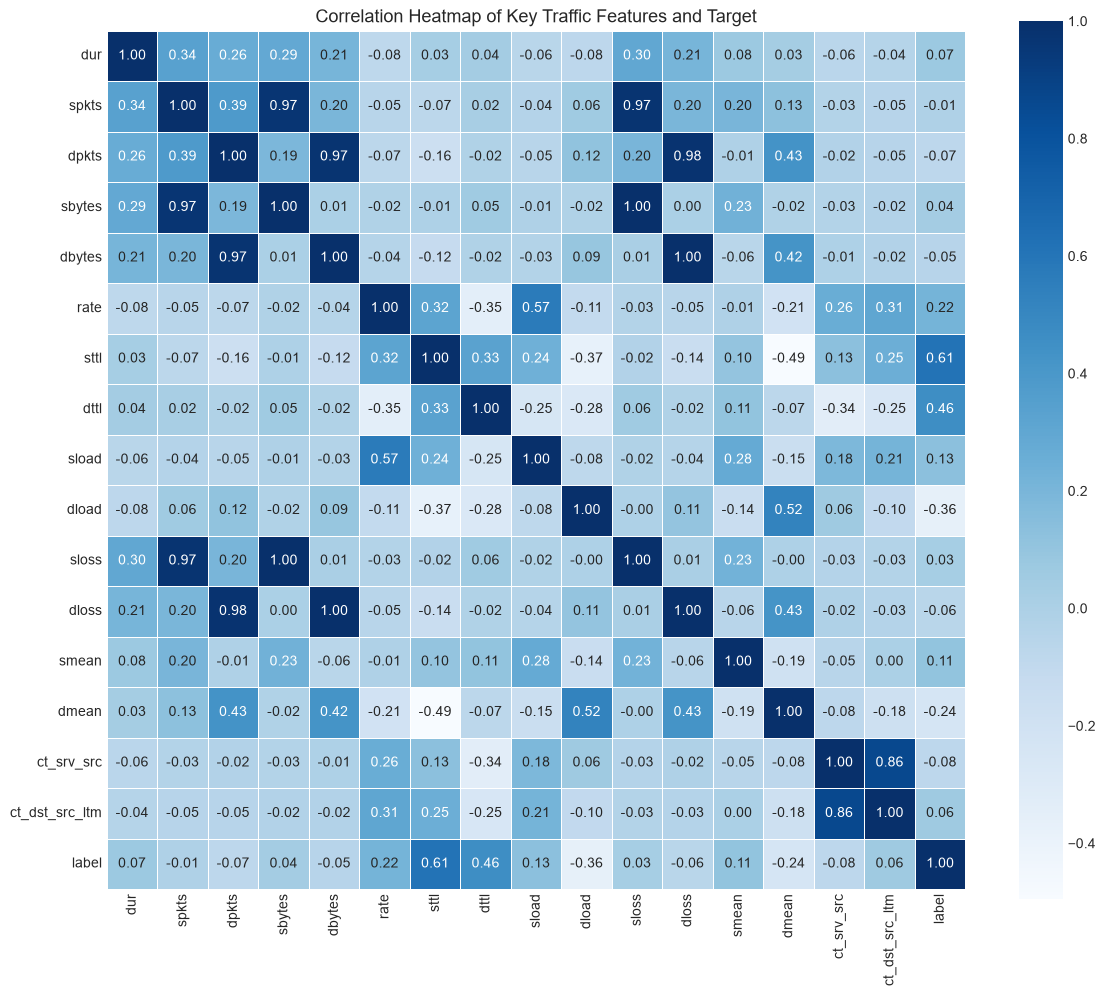

In [6]:
# Select representative numeric features for clear readability
key_numeric = [
    'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate',
    'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss',
    'smean', 'dmean', 'ct_srv_src', 'ct_dst_src_ltm', 'label'
]
valid_key_numeric = [c for c in key_numeric if c in train_clean.columns]
corr_matrix = train_clean[valid_key_numeric].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', cbar=True, square=True, linewidths=0.5)
plt.title('Correlation Heatmap of Key Traffic Features and Target', fontsize=13)
plt.tight_layout()
plt.show()

## 6. Distributions of Key Features (Normal vs Attack)

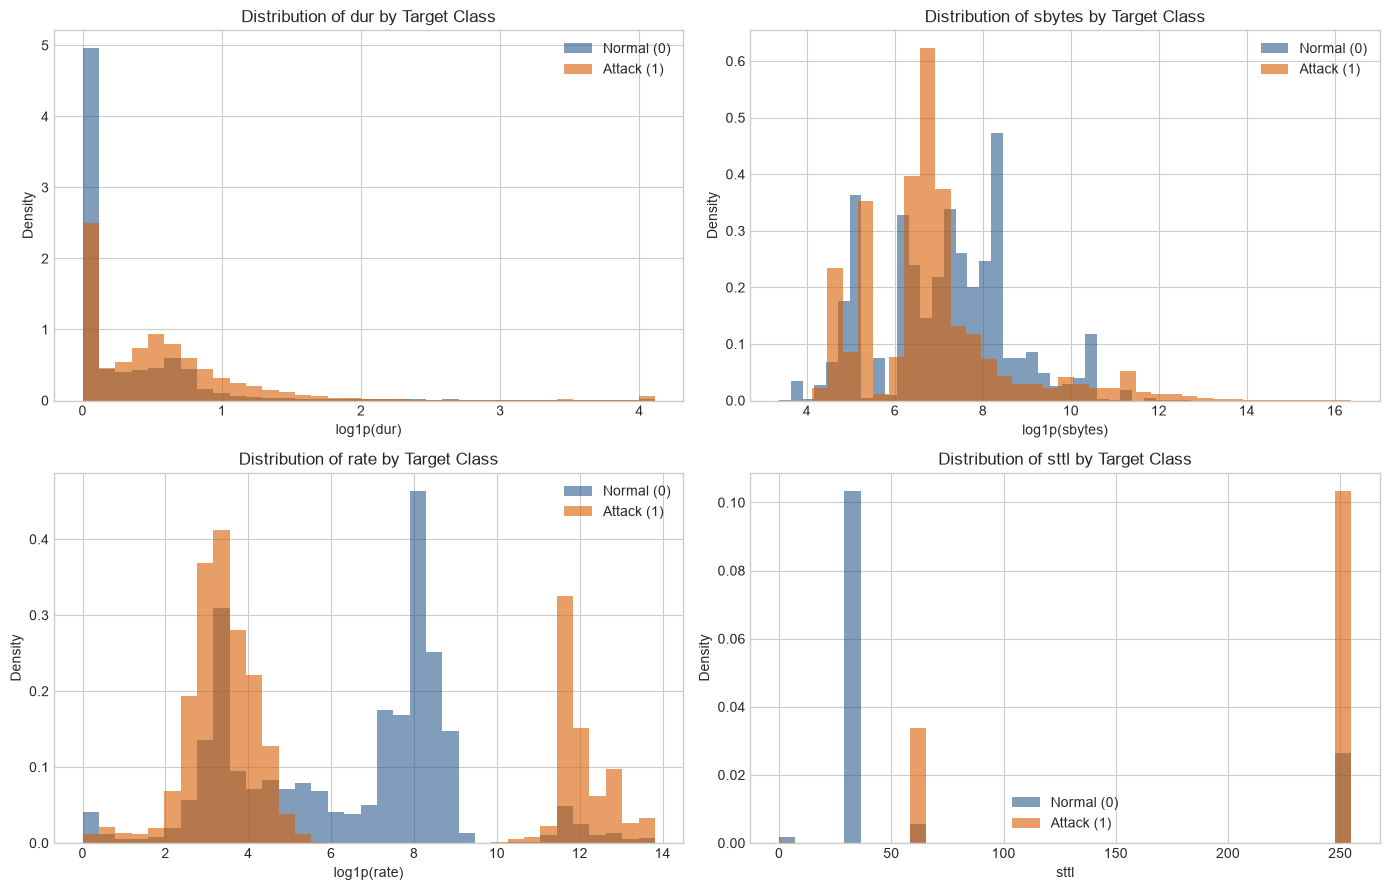

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
features_to_plot = ['dur', 'sbytes', 'rate', 'sttl']

for ax, feat in zip(axes.flat, features_to_plot):
    if feat in ['dur', 'sbytes', 'rate']:
        normal_vals = np.log1p(train_clean.loc[train_clean[config.BINARY_TARGET] == 0, feat])
        attack_vals = np.log1p(train_clean.loc[train_clean[config.BINARY_TARGET] == 1, feat])
        xlabel = f'log1p({feat})'
    else:
        normal_vals = train_clean.loc[train_clean[config.BINARY_TARGET] == 0, feat]
        attack_vals = train_clean.loc[train_clean[config.BINARY_TARGET] == 1, feat]
        xlabel = feat

    ax.hist(normal_vals, bins=35, alpha=0.6, color='#2b5c8f', label='Normal (0)', density=True)
    ax.hist(attack_vals, bins=35, alpha=0.6, color='#d95f02', label='Attack (1)', density=True)
    ax.set_title(f'Distribution of {feat} by Target Class')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Density')
    ax.legend()

plt.tight_layout()
plt.show()

## 7. Categorical Feature Distributions (proto, service, state)

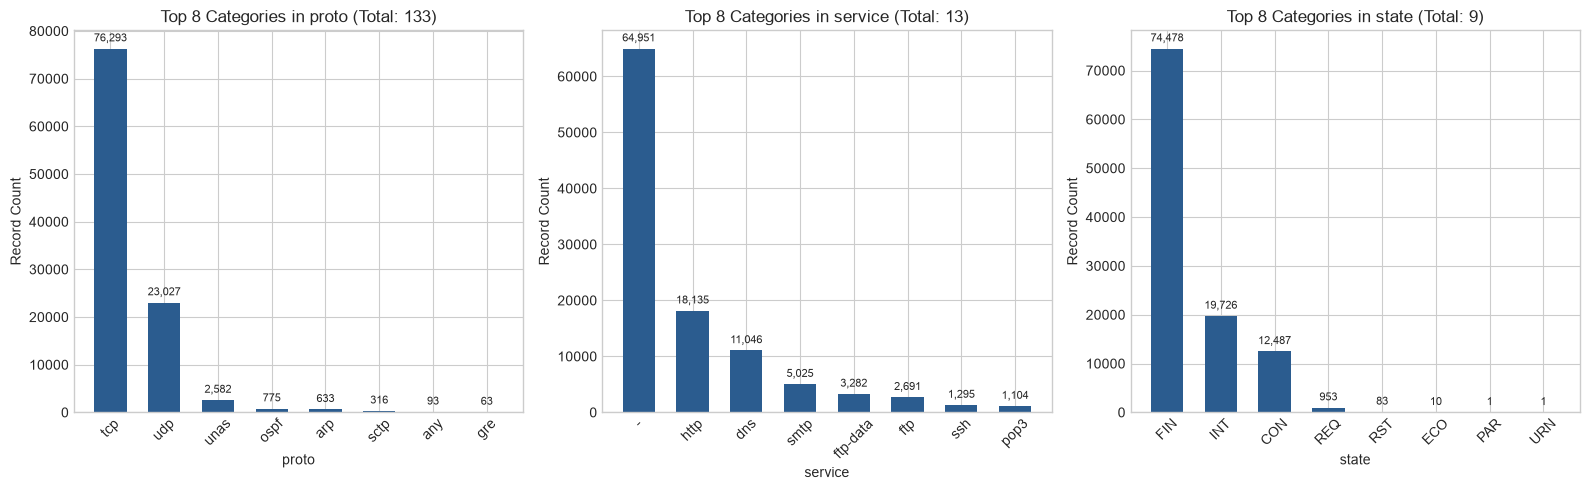

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, config.CATEGORICAL_COLS):
    top_categories = train_clean[col].value_counts().head(8)
    ax.bar(top_categories.index, top_categories.values, color='#2b5c8f', width=0.6)
    ax.set_title(f'Top 8 Categories in {col} (Total: {train_clean[col].nunique()})')
    ax.set_xlabel(col)
    ax.set_ylabel('Record Count')
    ax.tick_params(axis='x', rotation=45)
    for i, v in enumerate(top_categories.values):
        ax.text(i, v + (max(top_categories.values)*0.02), f'{v:,}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

## 8. Save Processed Datasets and Generate Sample Input CSV

In [9]:
# Save cleaned datasets to data/processed/
train_path, test_path = data_loader.save_processed(train_clean, test_clean)
print(f'Cleaned training set saved to: {train_path}')
print(f'Cleaned testing set saved to:  {test_path}')

# Generate stratified ~200 row sample input for web app and testing
sample_df = data_loader.create_sample_input(test_clean, target_samples=200)
print(f'\nSample input CSV generated at: {config.SAMPLE_INPUT_PATH}')
print(f'Sample dimensions: {sample_df.shape[0]} rows x {sample_df.shape[1]} feature columns')
print(f'Verified columns excluded: id={"id" in sample_df.columns}, label={"label" in sample_df.columns}, attack_cat={"attack_cat" in sample_df.columns}')

2026-10-29 01:08:47,144 [INFO] Saving cleaned training set (107740 rows) to C:\Users\Ankit007\OneDrive\Documents\final year project\data\processed\train_cleaned.parquet


2026-10-29 01:08:49,596 [INFO] Saving cleaned testing set (55945 rows) to C:\Users\Ankit007\OneDrive\Documents\final year project\data\processed\test_cleaned.parquet


2026-10-29 01:08:50,915 [INFO] Generating stratified sample of approx 200 rows from test set


2026-10-29 01:08:50,945 [INFO] Stratified sample generated with 200 total rows across 10 categories:
attack_cat
Normal            122
Exploits           27
Fuzzers            17
Generic            13
Reconnaissance     10
DoS                 6
Analysis            2
Backdoor            1
Shellcode           1
Worms               1


2026-10-29 01:08:50,953 [INFO] Saved sample input to: C:\Users\Ankit007\OneDrive\Documents\final year project\data\sample\sample_input.csv (200 rows, 42 feature columns)


Cleaned training set saved to: C:\Users\Ankit007\OneDrive\Documents\final year project\data\processed\train_cleaned.parquet
Cleaned testing set saved to:  C:\Users\Ankit007\OneDrive\Documents\final year project\data\processed\test_cleaned.parquet

Sample input CSV generated at: C:\Users\Ankit007\OneDrive\Documents\final year project\data\sample\sample_input.csv
Sample dimensions: 200 rows x 42 feature columns
Verified columns excluded: id=False, label=False, attack_cat=False
